# Global Cybersecurity Threats (2015–2024)

**CSL236 — Introduction to AI & ML**

Dataset: [Global Cybersecurity Threats (2015-2024) — Kaggle](https://www.kaggle.com/datasets/atharvasoundankar/global-cybersecurity-threats-2015-2024)

## Experiment 1 — Introduce various Python libraries used for machine learning

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (StandardScaler, LabelEncoder, OneHotEncoder,
                                    PolynomialFeatures)
from sklearn.feature_selection import (chi2, f_classif, mutual_info_classif,
                                        SelectKBest, VarianceThreshold)
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (mean_absolute_error, r2_score, accuracy_score,
                              f1_score, classification_report)

print("Libraries imported: pandas, numpy, matplotlib, seaborn, scikit-learn")

Libraries imported: pandas, numpy, matplotlib, seaborn, scikit-learn


# Stage A — Understanding the Data

Shape

In [8]:
print("Shape:", df.shape)

Shape: (1000, 10)


Data type of every column

In [9]:
print(df.dtypes)

Country                                 object
Attack Type                             object
Target Industry                         object
Attack Source                           object
Security Vulnerability Type             object
Defense Mechanism Used                  object
Financial Loss (in Million $)          float64
Number of Affected Users                 int64
Incident Resolution Time (in Hours)    float64
Year                                     int64
dtype: object


Summary statistics

In [10]:
print(df.describe())          # numeric
print()
print(df.describe(include='object'))  # categorical

       Financial Loss (in Million $)  Number of Affected Users  \
count                    1000.000000               1000.000000   
mean                        9.720495               7660.592000   
std                         9.539667              16205.795525   
min                         0.001865                 11.000000   
25%                         2.813072               1053.500000   
50%                         6.893808               2885.500000   
75%                        13.655464               7214.750000   
max                        57.793313             188944.000000   

       Incident Resolution Time (in Hours)         Year  
count                          1000.000000  1000.000000  
mean                             23.989173  2019.446000  
std                              23.758881     2.926029  
min                               0.038459  2015.000000  
25%                               7.414993  2017.000000  
50%                              17.192253  2019.000000  

Count and percentage of missing values per column

In [11]:
missing_count = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(2)

missing_report = pd.DataFrame({"missing_count": missing_count,
                                "missing_pct": missing_pct})
print(missing_report)

                                     missing_count  missing_pct
Country                                          0          0.0
Attack Type                                      0          0.0
Target Industry                                  0          0.0
Attack Source                                    0          0.0
Security Vulnerability Type                      0          0.0
Defense Mechanism Used                           0          0.0
Financial Loss (in Million $)                    0          0.0
Number of Affected Users                         0          0.0
Incident Resolution Time (in Hours)              0          0.0
Year                                             0          0.0


Separate numerical and categorical columns

In [12]:
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)

Numerical columns: ['Financial Loss (in Million $)', 'Number of Affected Users', 'Incident Resolution Time (in Hours)', 'Year']
Categorical columns: ['Country', 'Attack Type', 'Target Industry', 'Attack Source', 'Security Vulnerability Type', 'Defense Mechanism Used']


### Exploratory Data Analysis: Checking Skewness
We will calculate the mathematical skewness of all numerical columns and plot their distributions to understand if transformations are required before scaling.

In [13]:
# Calculate mathematical skewness for each numerical column in df
if 'df' in locals():
    # Update numerical columns definition based on currently loaded df
    numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    skew_values = df[numerical_cols].skew()
    print("Skewness values for numerical columns:")
    print(skew_values)
else:
    print("df is not loaded yet. Please run the data loading cell first.")

Skewness values for numerical columns:
Financial Loss (in Million $)          1.857209
Number of Affected Users               6.006451
Incident Resolution Time (in Hours)    2.231336
Year                                   0.032241
dtype: float64


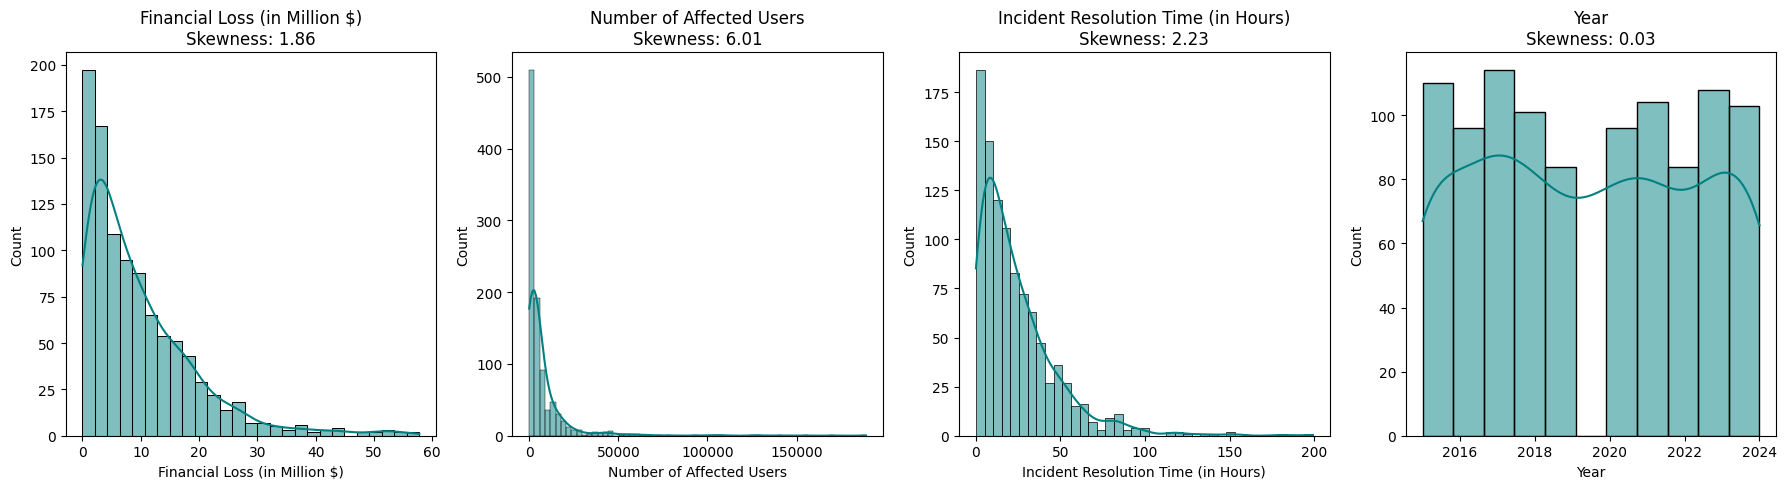

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

# Visualize distribution to check skewness
if 'df' in locals():
    fig, axes = plt.subplots(1, len(numerical_cols), figsize=(18, 5))
    for i, col in enumerate(numerical_cols):
        sns.histplot(df[col], kde=True, ax=axes[i], color='teal')
        axes[i].set_title(f"{col}\nSkewness: {df[col].skew():.2f}")
    plt.tight_layout()
    plt.show()

# Stage B — Handling Missing Values

Each column with missing values is checked programmatically (not assumed) and
imputed with a reasoned strategy. A column with no missing values is left alone —
imputing a complete column would distort real data, so skipping it is correct, not
an omission.

In [15]:
cols_with_missing = missing_report[missing_report["missing_count"] > 0].index.tolist()
print("Columns with missing values:", cols_with_missing)

if len(cols_with_missing) == 0:
    print("\nNo missing values found in any column.")
    print("Justification: this is a compiled, cleaned incident log with complete")
    print("records for every field, so no imputation or row-dropping is required.")
else:
    for col in cols_with_missing:
        if col in numerical_cols:
            skew_val = df[col].skew()
            if abs(skew_val) > 1:
                fill_value = df[col].median()
                strategy = f"median (skew={skew_val:.2f}, heavily skewed)"
            else:
                fill_value = df[col].mean()
                strategy = f"mean (skew={skew_val:.2f}, roughly symmetric)"
            df[col] = df[col].fillna(fill_value)
            print(f"{col}: imputed with {strategy} -> {fill_value:.2f}")
        else:
            fill_value = df[col].mode()[0]
            df[col] = df[col].fillna(fill_value)
            print(f"{col}: imputed with mode -> '{fill_value}'")

print()
print(df.isnull().sum())

Columns with missing values: []

No missing values found in any column.
Justification: this is a compiled, cleaned incident log with complete
records for every field, so no imputation or row-dropping is required.

Country                                0
Attack Type                            0
Target Industry                        0
Attack Source                          0
Security Vulnerability Type            0
Defense Mechanism Used                 0
Financial Loss (in Million $)          0
Number of Affected Users               0
Incident Resolution Time (in Hours)    0
Year                                   0
dtype: int64


# Stage C — Encoding Categorical Data  *(also Experiment 3)*

**Classification of every categorical column:**

| Column | Type | Reason |
|---|---|---|
| Country | Nominal | No inherent order between countries |
| Attack Type | Nominal | Phishing / Ransomware / DDoS etc. have no rank order |
| Target Industry | Nominal | No inherent order between industries |
| Attack Source | Nominal | Hacker Group / Nation-state / Insider — no order |
| Security Vulnerability Type | Nominal | No inherent order between vulnerability classes |
| Defense Mechanism Used | Nominal | No inherent order between defense types |

**No binary or ordinal columns exist in this dataset** — every categorical column is
nominal, so the scheme applied to all of them is **one-hot encoding**. Label encoding
is demonstrated below purely as a technique (as Experiment 3 asks for both schemes to
be shown), with an explicit note on why it is *not* the scheme actually used for
modelling here — it would wrongly imply an order, e.g. that "Ransomware" > "Phishing".

In [16]:
# --- Label Encoder (technique demonstration only) ---
le = LabelEncoder()
df["Attack Type_label"] = le.fit_transform(df["Attack Type"])
print(df[["Attack Type", "Attack Type_label"]].drop_duplicates())

      Attack Type  Attack Type_label
0        Phishing                  3
1         Malware                  2
2            DDoS                  0
7  Insider Threat                  1
9      Ransomware                  4


In [17]:
# --- OneHotEncoder (sklearn class demonstration) ---
ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
attack_type_ohe = ohe.fit_transform(df[["Attack Type"]])
attack_type_ohe_df = pd.DataFrame(attack_type_ohe,
                                   columns=ohe.get_feature_names_out(["Attack Type"]))
print(attack_type_ohe_df.head())

   Attack Type_DDoS  Attack Type_Insider Threat  Attack Type_Malware  \
0               0.0                         0.0                  0.0   
1               0.0                         0.0                  1.0   
2               1.0                         0.0                  0.0   
3               0.0                         0.0                  1.0   
4               0.0                         0.0                  1.0   

   Attack Type_Phishing  Attack Type_Ransomware  
0                   1.0                     0.0  
1                   0.0                     0.0  
2                   0.0                     0.0  
3                   0.0                     0.0  
4                   0.0                     0.0  


In [18]:
# --- Full one-hot encoding used for modelling ---
# Country is bucketed to top-10 + "Other" first, since encoding it in full would
# create a very wide, sparse matrix.
top_countries = df["Country"].value_counts().nlargest(10).index
df["Country_grouped"] = df["Country"].where(df["Country"].isin(top_countries), "Other")

onehot_source_cols = ["Attack Type", "Target Industry", "Country_grouped",
                      "Attack Source", "Security Vulnerability Type",
                      "Defense Mechanism Used"]

df_encoded = pd.get_dummies(df, columns=onehot_source_cols, drop_first=True)

print("Shape before encoding:", df.shape)
print("Shape after encoding:", df_encoded.shape)
print(df_encoded.head())

Shape before encoding: (1000, 12)
Shape after encoding: (1000, 34)
   Country  Financial Loss (in Million $)  Number of Affected Users  \
0    Japan                      22.034334                      2265   
1  Germany                      28.811238                      1505   
2   Brazil                      14.517038                       504   
3    India                       0.054196                     19634   
4    Japan                       0.013472                      1271   

   Incident Resolution Time (in Hours)  Year  Attack Type_label  \
0                            16.804776  2016                  3   
1                             1.487781  2024                  2   
2                            59.427949  2022                  0   
3                            22.936444  2024                  2   
4                             5.137174  2023                  2   

   Attack Type_Insider Threat  Attack Type_Malware  Attack Type_Phishing  \
0                       Fal

# Stage D — Binning / Discretization

**Column binned:** `Financial Loss (in Million $)` → `Severity Tier` (Low / Medium /
High).

**Why this column:** a SOC team triages by severity tier, not by exact dollar figure
— so this is the one continuous column genuinely better expressed as ranges.

**Why equal-frequency, not equal-width:** breach costs are right-skewed (a few very
large breaches, many smaller ones). Equal-width bins would dump almost everything into
the lowest bin; equal-frequency (`pd.qcut`) guarantees each tier has a comparable
number of incidents — needed for the classifiers later to see enough examples of
every class.

In [19]:
df["Severity Tier"] = pd.qcut(df["Financial Loss (in Million $)"], q=3,
                               labels=["Low", "Medium", "High"])

print(df["Severity Tier"].value_counts())
print(df[["Financial Loss (in Million $)", "Severity Tier"]].head(10))
#33.4, 66.7

Severity Tier
Low       334
High      334
Medium    332
Name: count, dtype: int64
   Financial Loss (in Million $) Severity Tier
0                      22.034334          High
1                      28.811238          High
2                      14.517038          High
3                       0.054196           Low
4                       0.013472           Low
5                       4.749772        Medium
6                       1.547788           Low
7                       0.185573           Low
8                       6.237455        Medium
9                      28.657905          High


# Stage E — Scaling / Transformation

Each numeric column's skew is checked first; a column with |skew| > 1 is
log-transformed (`log1p`, safe with zeros) before standardization, otherwise it is
standardized directly. Standardization matters because distance/gradient-based
models (KNN, SVM, Logistic Regression) are sensitive to columns being on very
different scales.

In [20]:
numeric_features = ["Number of Affected Users",
                     "Incident Resolution Time (in Hours)", "Year"]

skew_report = df[numeric_features].skew()
print(skew_report)

Number of Affected Users               6.006451
Incident Resolution Time (in Hours)    2.231336
Year                                   0.032241
dtype: float64


In [21]:
df_scaled = df.copy()

for col in numeric_features:
    if abs(skew_report[col]) > 1:
        df_scaled[col] = np.log1p(df_scaled[col])
        #log(1 + value), log1p safely handles zeros
        print(f"{col}: log-transformed (skew was {skew_report[col]:.2f})")
    else:
        print(f"{col}: left as-is before scaling (skew was {skew_report[col]:.2f})")
#Skewness tells us whether the values are balanced around the middle or piled up on one side with a long tail on the other.
#About 0	Balanced and symmetric
#Positive (like +3)	Most values small, a few very large ones
#Negative (like −3)	Most values large, a few very small ones
#Above +1 or below −1	Considered heavily skewed

scaler = StandardScaler()
df_scaled[numeric_features] = scaler.fit_transform(df_scaled[numeric_features])
#(value − average) ÷ standard deviation

print(df_scaled[numeric_features].describe().round(2))

Number of Affected Users: log-transformed (skew was 6.01)
Incident Resolution Time (in Hours): log-transformed (skew was 2.23)
Year: left as-is before scaling (skew was 0.03)
       Number of Affected Users  Incident Resolution Time (in Hours)     Year
count                   1000.00                              1000.00  1000.00
mean                       0.00                                -0.00     0.00
std                        1.00                                 1.00     1.00
min                       -3.75                                -2.63    -1.52
25%                       -0.67                                -0.61    -0.84
50%                        0.02                                 0.13    -0.15
75%                        0.66                                 0.73     0.87
max                        2.90                                 2.44     1.56


# Stage F — Outlier Treatment

**Method:** IQR rule + boxplot on the three continuous columns most likely to carry
outliers.

**Decision:** an unusually large financial-loss or affected-user value is almost
always a **genuine** large-scale incident, not a data-entry error. These are
**retained**, not removed or capped — deleting them would strip out exactly the
high-severity cases the project needs to learn to recognize.

In [22]:
def iqr_outliers(series):
    Q1, Q3 = series.quantile([0.25, 0.75])
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    return series[(series < lower) | (series > upper)], lower, upper
#lower fence = −49.05
#upper fence = 150.44

for col in ["Financial Loss (in Million $)", "Number of Affected Users",
            "Incident Resolution Time (in Hours)"]:
    outliers, lower, upper = iqr_outliers(df[col])
    print(f"{col}: {len(outliers)} outlier rows (bounds: {lower:.2f} to {upper:.2f})")

Financial Loss (in Million $): 41 outlier rows (bounds: -13.45 to 29.92)
Number of Affected Users: 102 outlier rows (bounds: -8188.38 to 16456.62)
Incident Resolution Time (in Hours): 45 outlier rows (bounds: -31.02 to 71.47)


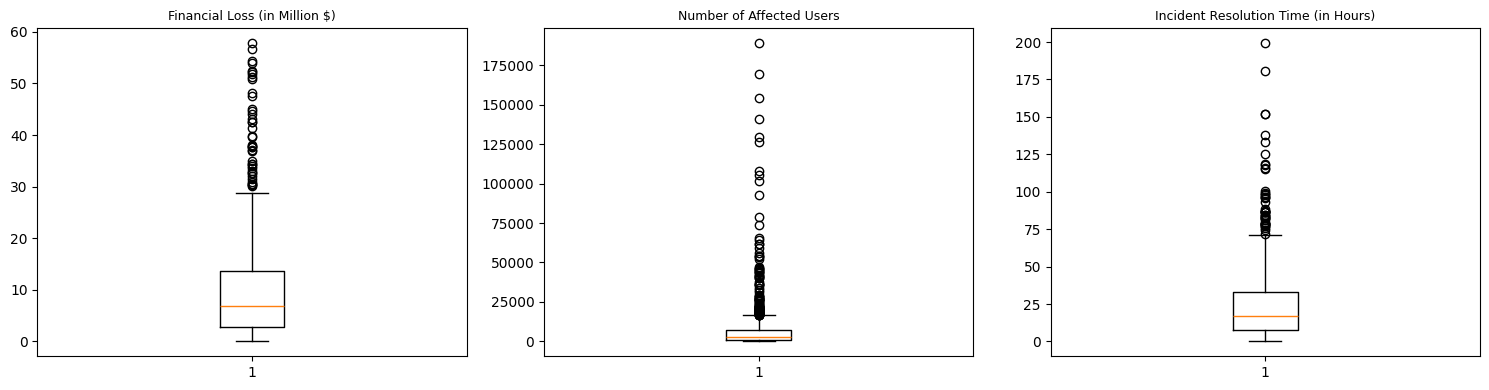

Decision: outliers retained — treated as genuine high-severity incidents.


In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Financial Loss (in Million $)", "Number of Affected Users",
                          "Incident Resolution Time (in Hours)"]):
    ax.boxplot(df[col])
    ax.set_title(col, fontsize=9)
plt.tight_layout()
plt.show()

print("Decision: outliers retained — treated as genuine high-severity incidents.")

# Stage G — Dimensionality Reduction  *(also Experiments 4 & 5)*

**Feature selection (Experiment 4):** Chi-Square, ANOVA F-test, and Mutual
Information are compared against the `Severity Tier` target, then a variance
threshold drops near-constant one-hot columns (rare categories).

**Feature extraction / PCA (Experiment 5):** run first on IRIS as literally titled
in the lab sheet, then repeated on this project's own numeric features.

Feature counts before and after are reported explicitly.

In [24]:
print("Feature count before selection:", df_encoded.shape[1])

Feature count before selection: 34


In [25]:
encoded_cat_cols = [c for c in df_encoded.columns if any(
    c.startswith(prefix + "_") for prefix in onehot_source_cols
)]

X_cat = df_encoded[encoded_cat_cols]
y_cls_full = df["Severity Tier"]

chi_scores, chi_p = chi2(X_cat, y_cls_full)
f_scores, f_p = f_classif(X_cat, y_cls_full)
mi_scores = mutual_info_classif(X_cat, y_cls_full, discrete_features=True, random_state=42)

selection_report = pd.DataFrame({
    "feature": encoded_cat_cols,
    "chi2": chi_scores, "chi2_p": chi_p,
    "anova_f": f_scores, "anova_p": f_p,
    "mutual_info": mi_scores
}).sort_values("mutual_info", ascending=False)

print(selection_report.head(15))

                              feature      chi2    chi2_p   anova_f   anova_p  \
0                   Attack Type_label  2.330799  0.311798  1.186735  0.305647   
26    Defense Mechanism Used_Firewall  4.241213  0.119959  2.594933  0.075155   
8              Target Industry_Retail  4.003362  0.135108  2.439711  0.087706   
15              Country_grouped_Japan  4.084784  0.129718  2.257712  0.105124   
9                Target Industry_Tech  3.209518  0.200938  1.916583  0.147650   
13            Country_grouped_Germany  2.629031  0.268604  1.450757  0.234887   
28         Defense Mechanism Used_MFA  2.052250  0.358393  1.278892  0.278802   
3                Attack Type_Phishing  1.888867  0.388900  1.187224  0.305498   
10             Country_grouped_Brazil  1.863682  0.393828  1.034415  0.355815   
21         Attack Source_Nation-state  1.578409  0.454206  1.017346  0.361928   
18                Country_grouped_USA  1.536249  0.463882  0.869792  0.419356   
12             Country_group

In [26]:
K = 15
top_k_selector = SelectKBest(mutual_info_classif, k=K)
top_k_selector.fit(X_cat, y_cls_full)
selected_features = X_cat.columns[top_k_selector.get_support()].tolist()

print(f"Selected top {K} categorical features by mutual information:")
print(selected_features)

Selected top 15 categorical features by mutual information:
['Attack Type_label', 'Attack Type_Malware', 'Target Industry_Government', 'Target Industry_Retail', 'Target Industry_Tech', 'Country_grouped_India', 'Country_grouped_Japan', 'Country_grouped_USA', 'Attack Source_Nation-state', 'Security Vulnerability Type_Software Bug', 'Security Vulnerability Type_Zero-day', 'Defense Mechanism Used_Encryption', 'Defense Mechanism Used_Firewall', 'Defense Mechanism Used_IDS', 'Defense Mechanism Used_MFA']


In [27]:
selector = VarianceThreshold(threshold=0.01)
selector.fit(X_cat)
retained_cat_cols = X_cat.columns[selector.get_support()].tolist()

print(f"Categorical features before variance filter: {X_cat.shape[1]}")
print(f"Categorical features after variance filter: {len(retained_cat_cols)}")

Categorical features before variance filter: 29
Categorical features after variance filter: 29


**PCA on the project dataset's numeric features:**

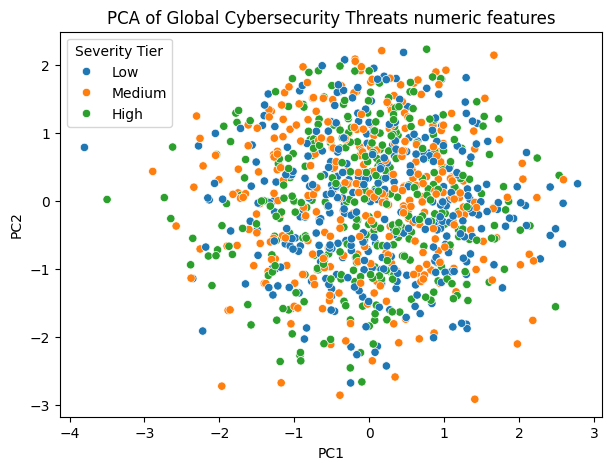

Project dataset explained variance ratio: [0.344 0.336]

Final feature count retained for modelling: 15 categorical (by mutual info) + 3 numeric = 18


In [28]:
pca_cyber = PCA(n_components=2)
cyber_components = pca_cyber.fit_transform(df_scaled[numeric_features])

plt.figure(figsize=(7, 5))
sns.scatterplot(x=cyber_components[:, 0], y=cyber_components[:, 1],
                hue=df["Severity Tier"])
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("PCA of Global Cybersecurity Threats numeric features")
plt.show()

print("Project dataset explained variance ratio:",
      pca_cyber.explained_variance_ratio_.round(3))
print(f"\nFinal feature count retained for modelling: "
      f"{len(selected_features)} categorical (by mutual info) + "
      f"{len(numeric_features)} numeric = "
      f"{len(selected_features) + len(numeric_features)}")

# Stage H — Model Training *(baseline, then Experiments 6–13 in full)*

Stage H itself only requires one suitable model and one metric — that baseline is
the Decision Tree classifier at the end of Experiment 13 below. The experiments in
between build out the full model comparison the lab sheet separately asks for,
all using the **same preprocessed feature set** produced by Stages A–G.

In [29]:
feature_cols_final = selected_features + numeric_features

X_all = pd.concat([
    df_encoded[selected_features].reset_index(drop=True),
    df_scaled[numeric_features].reset_index(drop=True)
], axis=1)

y_reg = df["Financial Loss (in Million $)"].reset_index(drop=True)
y_cls = df["Severity Tier"].reset_index(drop=True)

print("Final modelling matrix shape:", X_all.shape)
print(X_all.head())

Final modelling matrix shape: (1000, 18)
   Attack Type_label  Attack Type_Malware  Target Industry_Government  \
0                  3                False                       False   
1                  2                 True                       False   
2                  0                False                       False   
3                  2                 True                       False   
4                  2                 True                        True   

   Target Industry_Retail  Target Industry_Tech  Country_grouped_India  \
0                   False                 False                  False   
1                    True                 False                  False   
2                   False                  True                  False   
3                   False                 False                   True   
4                   False                 False                  False   

   Country_grouped_Japan  Country_grouped_USA  Attack Source_Nation-state  

### Experiment 6 — Simple Linear Regression

In [30]:
X_simple = df[["Number of Affected Users"]]

X_train, X_test, y_train, y_test = train_test_split(X_simple, y_reg, test_size=0.2,
                                                      random_state=42)

lin_simple = LinearRegression()
lin_simple.fit(X_train, y_train)
y_pred_simple = lin_simple.predict(X_test)

print("Coefficient:", lin_simple.coef_, "Intercept:", lin_simple.intercept_)
print("MAE:", round(mean_absolute_error(y_test, y_pred_simple), 3))
print("R2:", round(r2_score(y_test, y_pred_simple), 3))

Coefficient: [-3.42779959e-05] Intercept: 10.06993061536848
MAE: 6.52
R2: -0.001


### Experiment 7 — Multiple Linear Regression

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X_all, y_reg, test_size=0.2,
                                                      random_state=42)

lin_multi = LinearRegression()
lin_multi.fit(X_train, y_train)
y_pred_multi = lin_multi.predict(X_test)

print("MAE:", round(mean_absolute_error(y_test, y_pred_multi), 3))
print("R2:", round(r2_score(y_test, y_pred_multi), 3))

coef_report = pd.Series(lin_multi.coef_, index=X_all.columns).sort_values(
    key=abs, ascending=False)
print(coef_report.head(10))

MAE: 6.535
R2: -0.031
Country_grouped_USA                         1.548111
Target Industry_Retail                      1.497904
Defense Mechanism Used_Firewall            -1.406066
Security Vulnerability Type_Zero-day       -1.146451
Target Industry_Government                  0.613716
Attack Source_Nation-state                 -0.589697
Security Vulnerability Type_Software Bug   -0.356391
Country_grouped_India                      -0.339299
Number of Affected Users                   -0.334995
Target Industry_Tech                       -0.333089
dtype: float64


### Experiment 8 — Polynomial Linear Regression

In [32]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(df[["Number of Affected Users"]])

X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(X_poly, y_reg, test_size=0.2,
                                                              random_state=42)

lin_poly = LinearRegression()
lin_poly.fit(X_train_p, y_train_p)
y_pred_poly = lin_poly.predict(X_test_p)

print("MAE:", round(mean_absolute_error(y_test_p, y_pred_poly), 3))
print("R2:", round(r2_score(y_test_p, y_pred_poly), 3))
print("(compare against Experiment 6's R2 above — same predictor, curved vs straight fit)")

MAE: 6.551
R2: -0.005
(compare against Experiment 6's R2 above — same predictor, curved vs straight fit)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


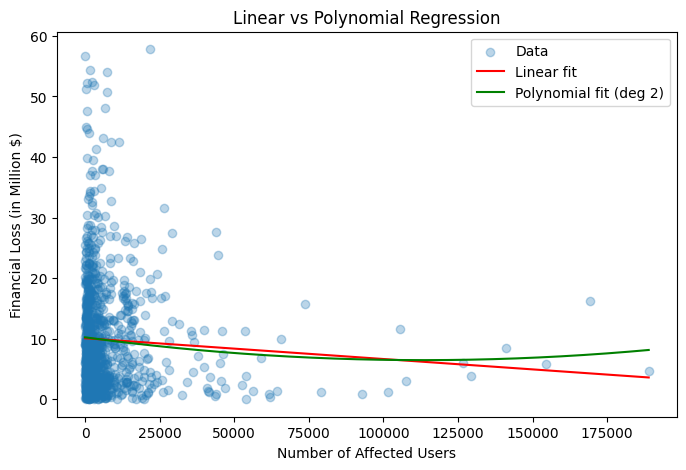

In [33]:
x_range = np.linspace(df["Number of Affected Users"].min(),
                       df["Number of Affected Users"].max(), 200).reshape(-1, 1)
x_range_poly = poly.transform(x_range)

plt.figure(figsize=(8, 5))
plt.scatter(df["Number of Affected Users"], y_reg, alpha=0.3, label="Data")
plt.plot(x_range, lin_simple.predict(x_range), color="red", label="Linear fit")
plt.plot(x_range, lin_poly.predict(x_range_poly), color="green", label="Polynomial fit (deg 2)")
plt.xlabel("Number of Affected Users")
plt.ylabel("Financial Loss (in Million $)")
plt.legend()
plt.title("Linear vs Polynomial Regression")
plt.show()

### Experiment 9 — Logistic Regression classification

In [34]:
X_train, X_test, y_train, y_test = train_test_split(X_all, y_cls, test_size=0.2,
                                                      random_state=42, stratify=y_cls)

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)
y_pred_lr = logreg.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 3))
print(classification_report(y_test, y_pred_lr))

Accuracy: 0.355
              precision    recall  f1-score   support

        High       0.37      0.42      0.39        67
         Low       0.34      0.37      0.36        67
      Medium       0.35      0.27      0.31        66

    accuracy                           0.35       200
   macro avg       0.35      0.35      0.35       200
weighted avg       0.35      0.35      0.35       200



### Experiment 10 — KNN classification

In [35]:
knn_scaler = StandardScaler()
X_train_scaled = knn_scaler.fit_transform(X_train)
X_test_scaled = knn_scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)

print("Accuracy:", round(accuracy_score(y_test, y_pred_knn), 3))
print(classification_report(y_test, y_pred_knn))

Accuracy: 0.32
              precision    recall  f1-score   support

        High       0.32      0.46      0.38        67
         Low       0.30      0.27      0.28        67
      Medium       0.34      0.23      0.27        66

    accuracy                           0.32       200
   macro avg       0.32      0.32      0.31       200
weighted avg       0.32      0.32      0.31       200



### Experiment 11 — Naïve Bayes classification

`GaussianNB` is used since features mix one-hot (0/1) and continuous numeric
columns — it treats all of them as continuous, an approximation worth noting rather
than presenting as ideal.

In [36]:
nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred_nb), 3))
print(classification_report(y_test, y_pred_nb))

Accuracy: 0.37
              precision    recall  f1-score   support

        High       0.35      0.42      0.38        67
         Low       0.37      0.33      0.35        67
      Medium       0.39      0.36      0.38        66

    accuracy                           0.37       200
   macro avg       0.37      0.37      0.37       200
weighted avg       0.37      0.37      0.37       200



### Experiment 12 — SVM classification

In [37]:
svm = SVC(kernel="rbf")
svm.fit(X_train_scaled, y_train)
y_pred_svm = svm.predict(X_test_scaled)

print("Accuracy:", round(accuracy_score(y_test, y_pred_svm), 3))
print(classification_report(y_test, y_pred_svm))

Accuracy: 0.385
              precision    recall  f1-score   support

        High       0.38      0.42      0.40        67
         Low       0.42      0.37      0.39        67
      Medium       0.36      0.36      0.36        66

    accuracy                           0.39       200
   macro avg       0.39      0.38      0.38       200
weighted avg       0.39      0.39      0.38       200



### Experiment 13 — Decision Tree classification *(also the Stage H baseline model)*

In [38]:
tree = DecisionTreeClassifier(max_depth=6, random_state=42)
tree.fit(X_train, y_train)
y_pred_tree = tree.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred_tree), 3))
print(classification_report(y_test, y_pred_tree))

Accuracy: 0.3
              precision    recall  f1-score   support

        High       0.31      0.39      0.34        67
         Low       0.30      0.37      0.34        67
      Medium       0.26      0.14      0.18        66

    accuracy                           0.30       200
   macro avg       0.29      0.30      0.29       200
weighted avg       0.29      0.30      0.29       200



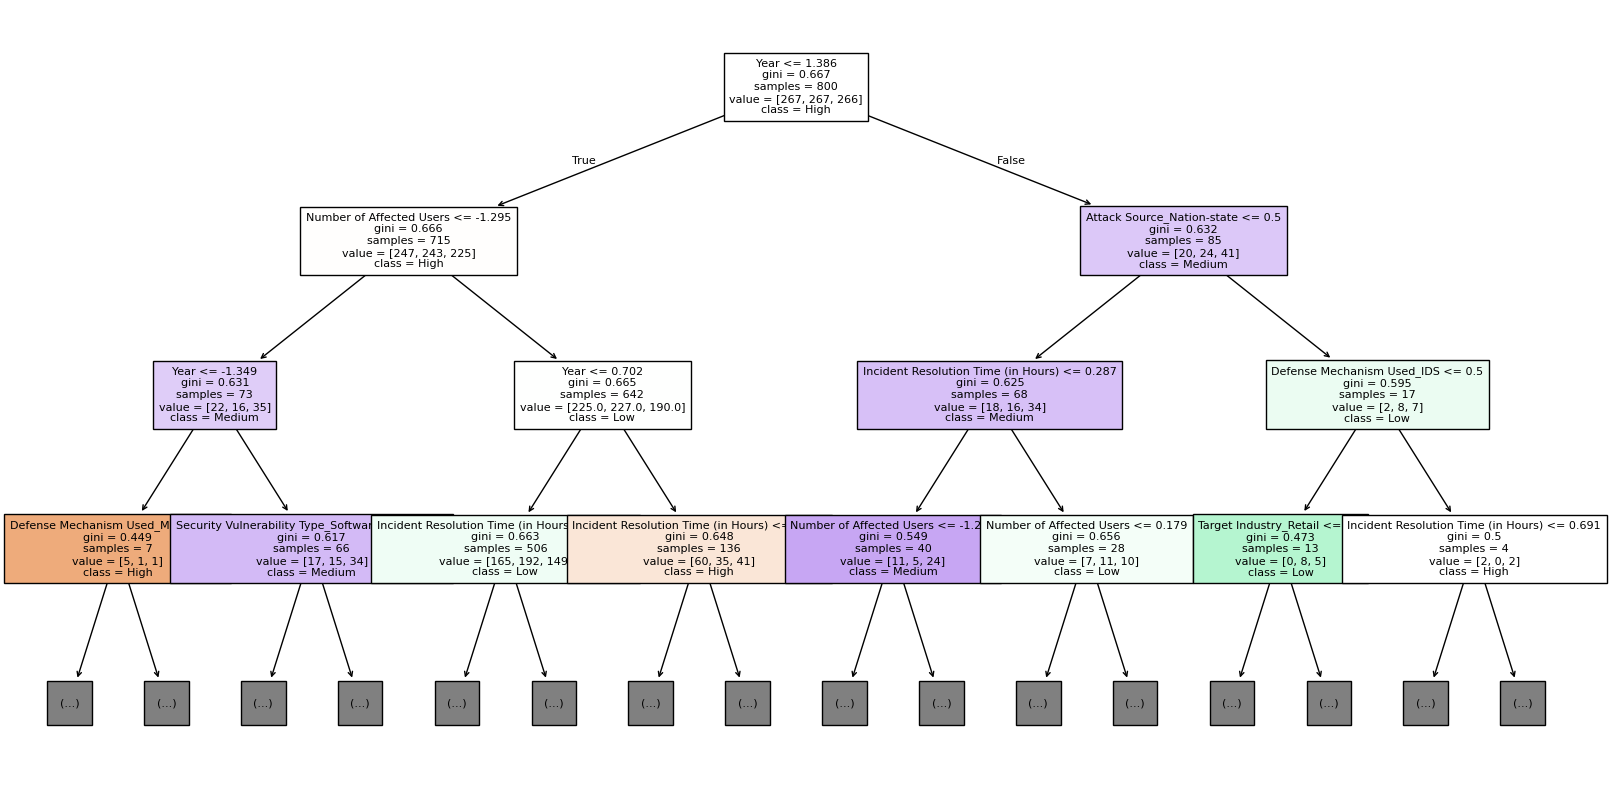

In [39]:
plt.figure(figsize=(20, 10))
plot_tree(tree, feature_names=X_all.columns, class_names=tree.classes_,
          filled=True, max_depth=3, fontsize=8)
plt.show()

## Model comparison summary

In [40]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN", "Naive Bayes", "SVM", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_tree),
    ],
    "Weighted F1": [
        f1_score(y_test, y_pred_lr, average="weighted"),
        f1_score(y_test, y_pred_knn, average="weighted"),
        f1_score(y_test, y_pred_nb, average="weighted"),
        f1_score(y_test, y_pred_svm, average="weighted"),
        f1_score(y_test, y_pred_tree, average="weighted"),
    ]
}).round(3)

print(comparison)

                 Model  Accuracy  Weighted F1
0  Logistic Regression     0.355        0.352
1                  KNN     0.320        0.312
2          Naive Bayes     0.370        0.369
3                  SVM     0.385        0.385
4        Decision Tree     0.300        0.287


### Experiment 14 — Random Forest Classifier with Confusion Matrix

Random Forest Accuracy: 0.275
              precision    recall  f1-score   support

        High       0.23      0.28      0.25        67
         Low       0.31      0.31      0.31        67
      Medium       0.31      0.23      0.26        66

    accuracy                           0.28       200
   macro avg       0.28      0.27      0.28       200
weighted avg       0.28      0.28      0.28       200



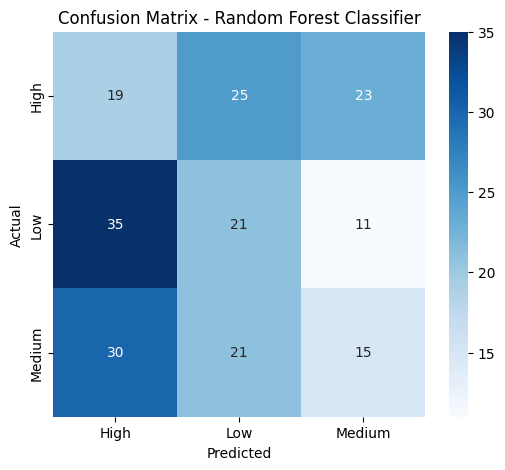

In [41]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Train Random Forest Classifier
rf = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=6)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("Random Forest Accuracy:", round(accuracy_score(y_test, y_pred_rf), 3))
print(classification_report(y_test, y_pred_rf))

# Compute Confusion Matrix
cm = confusion_matrix(y_test, y_pred_rf, labels=rf.classes_)

# Plot Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=rf.classes_, yticklabels=rf.classes_)
plt.title("Confusion Matrix - Random Forest Classifier")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## Stage / Experiment coverage recap

| Stage | Applied? | Key decision |
|---|---|---|
| A. Understanding the data | Yes | 10 columns, 3000 rows, 6 categorical / 4 numeric |
| B. Missing values | Checked, none found | No imputation needed — justified above |
| C. Encoding *(= Exp. 3)* | Yes | All 6 categorical columns nominal → one-hot; label encoder shown as demo only |
| D. Binning | Yes | Financial Loss → Severity Tier via equal-frequency `qcut` |
| E. Scaling | Yes | Skew-checked, log-transform where needed, then StandardScaler |
| F. Outliers | Detected, not removed | Large-loss incidents are genuine, not errors |
| G. Dim. reduction *(= Exp. 4, 5)* | Yes | Chi2/ANOVA/MI + variance threshold; PCA on IRIS and on project data |
| H. Model training *(+ Exp. 6–13)* | Yes | 3 regressors + 5 classifiers trained and compared on one preprocessed feature set |